#### Facility Problem using NSGA

Multi-Objective Facility Location Implementation, a constrained problem using the NSGA-II (Non-dominated Sorting Genetic Algorithm II) algorithm from the pymoo framework.



**Problem Definition (Facility Class)**
Objective function, $f_1$ (minimize distance to won facility) computes the Euclidean distance between the candidate location $(x_1, x_2)$ and your current facility located at $(3, 1)$. The $f_2$ (maximize distance to competitor) computes the Euclidean distance to a competitor's facility located at $(2, 4)$. Because pymoo inherently minimizes objectives, this maximization objective is formulated as minimizing the negative distance.
- Minimize $f_1(x_1, x_2) =\sqrt{(x_1 -3)^2 + (x_2 -1)^2}$, distance between company facilities.  
- Maximize $f_2(x_1, x_2) = -\sqrt{(x_1 -2)^2 + (x_2 -4)^2}$, distance between a new facility and a competitor's facility.

**Constraints**
- Zoning regulations $g_1(x_1, x_2) = x_1 + 2*x_2 -6 <=0$, and
- Property boundaries $g_2(x_1, x_2) = 2*x_1 -x_2 -2 <=0$,

**Search Space** bounded between $[0, 5]$ for both coordinate dimensions ($x_1$$x_1$ and $x_2$$x_2$).
- $0 \le x_1, x_2 \le 5$, boundary constrains

**Genetic Algorithm Configuration (NSGA2 Setup)**

Population Size, 50 candidate solutions.
Operators include
- **Sampling**, FloatRandomSampling that generates the initial population
- **Crossover**, Simulated Binary Crossover (SBX) with a probability of 0.8 is used to combine parent traits.
- **Mutation**, Polynomial Mutation (PM) with a probability of 0.6 is coupled with a RoundingRepair mechanism to ensure integer or discrete step compliance.
- **Termination**, the search runs for exactly 50 generations.

**Post-Processing & Multi-Criteria Decision Making (MCDM)**

Boundary Profiling identifies the approximate ideal (best possible values per objective) and nadir (worst possible values on the Pareto front) points to define normalized boundaries.
Achievement Scalarizing Function (ASF) decomposition technique acts as a decision-maker by using a weight vector [0.2, 0.8] (prioritizing the second objective, i.e., staying away from competitors) to find the single best compromise location.

In [3]:
!pip install pymoo > /dev/null

In [4]:
import numpy as np
from pymoo.core.problem import ElementwiseProblem

from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.operators.crossover.sbx import SBX
from pymoo.operators.mutation.pm import PolynomialMutation
from pymoo.operators.repair.rounding import RoundingRepair
from pymoo.operators.sampling.rnd import FloatRandomSampling

from pymoo.termination import get_termination
from pymoo.optimize import minimize
from pymoo.visualization.scatter import Scatter
from pymoo.decomposition.asf import ASF

import math
import matplotlib.pyplot as plt

In [5]:
class Facility(ElementwiseProblem):
    """
    A multi-objective optimization problem for facility location.

    Objectives:
    1. f1: Minimize distance between company facilities.
    2. f2: Maximize distance to a competitor's facility (formulated as minimizing the negative distance).

    Constraints:
    1. g1: Zoning regulations constraint.
    2. g2: Environmental/property boundary constraint.
    """
    def __init__(self) -> None:
        # Initialize problem with 2 variables, 2 objectives, 2 inequality constraints,
        # and variable boundaries between 0 and 5.
        super().__init__(n_var=2, n_obj=2, n_ieq_constr=2,
                         xl=np.array([0.0, 0.0]), xu=np.array([5.0, 5.0]))

    def _evaluate(self, x: np.ndarray, out: dict, *args, **kwargs) -> None:
        # Objective 1: Minimize distance to own facility at (3, 1)
        f1 = math.sqrt((x[0] - 3)**2 + (x[1] - 1)**2)
        # Objective 2: Maximize distance to competitor's facility at (2, 4)
        f2 = -math.sqrt((x[0] - 2)**2 + (x[1] - 4)**2)

        # Constraint 1: Zoning regulation x1 + 2*x2 <= 6
        g1 = x[0] + 2*x[1] - 6
        # Constraint 2: Environmental constraint 2*x1 - x2 <= 2
        g2 = 2*x[0] - x[1] - 2

        out["F"] = [f1, f2]
        out["G"] = [g1, g2]

# Instantiate the optimization problem
problem = Facility()

# Configure the NSGA-II genetic algorithm
algorithm = NSGA2(
    pop_size=50,
    sampling=FloatRandomSampling(),
    crossover=SBX(prob=0.8),
    mutation=PolynomialMutation(prob=0.6, repair=RoundingRepair()),
    eliminate_duplicates=True
)

# Set the termination condition to 50 generations
termination = get_termination("n_gen", 50)

# Execute the optimization run
res = minimize(
            problem,
            algorithm,
            termination,
            seed=1,
            save_history=True,
            verbose=True)

X = res.X
F = res.F

n_gen  |  n_eval  | n_nds  |     cv_min    |     cv_avg    |      eps      |   indicator  
     1 |       50 |      3 |  0.000000E+00 |  4.0133037898 |             - |             -
     2 |       83 |      5 |  0.000000E+00 |  1.9383798402 |  0.2958735650 |         ideal
     3 |       91 |      5 |  0.000000E+00 |  1.9383798402 |  0.000000E+00 |             f
     4 |       99 |      5 |  0.000000E+00 |  1.9383798402 |  0.000000E+00 |             f
     5 |      107 |      5 |  0.000000E+00 |  1.9383798402 |  0.000000E+00 |             f
     6 |      114 |      5 |  0.000000E+00 |  1.9383798402 |  0.000000E+00 |             f
     7 |      123 |      5 |  0.000000E+00 |  1.9383798402 |  0.000000E+00 |             f
     8 |      131 |      5 |  0.000000E+00 |  1.9383798402 |  0.000000E+00 |             f
     9 |      138 |      5 |  0.000000E+00 |  1.9383798402 |  0.000000E+00 |             f
    10 |      145 |      5 |  0.000000E+00 |  1.9383798402 |  0.000000E+00 |             f

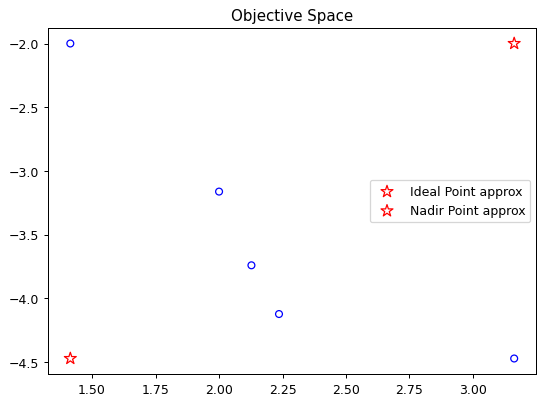

In [6]:
approx_ideal = F.min(axis=0)
approx_nadir = F.max(axis=0)

plt.figure(figsize=(7, 5), dpi=90)
plt.scatter(F[:, 0], F[:, 1], s=30, facecolors='none', edgecolors='b')
plt.scatter(approx_ideal[0], approx_ideal[1], facecolors='none', edgecolors='r', marker='*', s=100, label='Ideal Point approx')
plt.scatter(approx_nadir[0], approx_nadir[1], facecolors='none', edgecolors='r', marker='*', s=100, label='Nadir Point approx')
plt.title("Objective Space")
plt.legend()
plt.show()

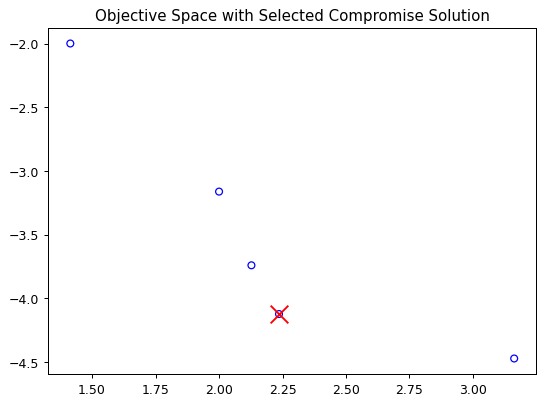

In [7]:
# Initialize Achievement Scalarizing Function (ASF) decomposition
decomp = ASF()

# Define preference weights for the objectives (e.g., placing more importance on the second objective)
weights = np.array([0.2, 0.8])

# Normalize the objective space values using approximated ideal and nadir points
nF = (F - approx_ideal) / (approx_nadir - approx_ideal)

# Find the index of the solution that minimizes the ASF metric
i = decomp.do(nF, 1/weights).argmin()

# Plot the objective space and highlight the chosen compromise solution
plt.figure(figsize=(7, 5), dpi=90)
plt.scatter(F[:, 0], F[:, 1], s=30, facecolors='none', edgecolors='b')
plt.scatter(F[i, 0], F[i, 1], color='r', s=200, marker='x')
plt.title("Objective Space with Selected Compromise Solution")
plt.show()

In [8]:
soln = np.asarray(X[i], dtype='int')
print('Best solution found')
print('Optimal facility location', soln)
print('Optimal distance between facilities', round(F[i, 0], 2))
print('Optimal distance between new facility and competitors', round(-F[i, 1], 2))

Best solution found
Optimal facility location [1 0]
Optimal distance between facilities 2.24
Optimal distance between new facility and competitors 4.12
